# 03 · Quebras estruturais e hipóteses de negócio

**Objetivo:**
- identificar e testar formalmente as mudanças de nível da demanda;
- investigar se a **quebra final** (fev/2025) está associada à entrada de novos clientes;
- investigar se a **quebra inicial** (mudança do horário de funcionamento em 2024) provocou canibalização.

**Sem vazamento:** as quebras usadas na modelagem são detectadas **apenas com o treino** (até 09/03/2025), e em cada origem do backtest com os dados até ela. As análises de clientes e de canibalização são retrospectivas e usam a série inteira, porque não alimentam a previsão.

| Seção | Módulo |
|---|---|
| 1. Detecção e testes formais | `src/structural_breaks/structural_break_test.py` |
| 2. Quebra inicial: janela de vendas | idem |
| 3. Quebra final: novos clientes | `src/structural_breaks/customer_analysis.py` |
| 4. Canibalização | `src/structural_breaks/cannibalization_analysis.py` |
| 5. Datas das dummies | síntese |

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

from src.visualization.plots import aplicar_tema
aplicar_tema()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


def mostrar(fig):
    """Exibe a figura uma única vez e libera a memória."""
    display(fig)
    plt.close(fig)

from src.data.preprocessing import preparar_base
from src.structural_breaks import structural_break_test as sb, customer_analysis as ca, cannibalization_analysis as cn

base = preparar_base()
ORIGEM = pd.Timestamp("2025-03-09")
r = sb.bateria_testes(base.series, base.transacoes, ORIGEM)

2026-11-10 19:10:11 | INFO    | src.data.load_data | Dados brutos conferidos com o MANIFEST.json (SHA-256)


2026-11-10 19:10:11 | INFO    | src.data.load_data | index_1.csv: 3636 registros válidos (máquina 1)


2026-11-10 19:10:11 | INFO    | src.data.load_data | index_2.csv: 262 registros válidos (máquina 2)


2026-11-10 19:10:11 | INFO    | src.data.preprocessing | Séries diárias construídas: {('Máquina 1', 'demanda'): 388, ('Máquina 1', 'receita'): 388, ('Máquina 2', 'demanda'): 44, ('Máquina 2', 'receita'): 44, ('Total', 'demanda'): 388, ('Total', 'receita'): 388}


2026-11-10 19:10:11 | INFO    | src.structural_breaks.structural_break_test | Quebras (até 09/03/2025): {'Máquina 1': ['24/07/2024', '16/11/2024', '30/01/2025'], 'Total': ['24/07/2024', '16/11/2024', '04/02/2025']} | janela 18/05/2024


## 1. Detecção e testes formais de quebra de nível

**Detecção** (porte de `modelagens_testes`, seção 4.2): Segmentação Binária com custo L2 e segmentos de pelo menos 28 dias; o número de quebras é escolhido por **BIC**. Como o BIC supõe erros independentes, a escolha é refeita com o **tamanho efetivo de amostra** n·(1 − r₁)/(1 + r₁).

**Testes formais.** Uma data escolhida olhando os dados torna inválido o p-valor de um teste de Chow comum. Por isso:

| Teste | H0 | Por que |
|---|---|---|
| **sup-Wald de Andrews (1993)**, erros HAC | nenhuma quebra de nível em [15%, 85%] da amostra | data desconhecida; p-valor da distribuição assintótica correta (ponte browniana simulada) |
| **OLS-CUSUM** | parâmetros estáveis | teste geral de instabilidade |
| **Razão de verossimilhança** Poisson/NB2 | dummies de regime = 0 | modelo de contagem com dia da semana |
| **Regressão segmentada** (HAC) | sem salto de nível / sem mudança de inclinação | separa nível de tendência |
| **sup-Wald local** | sem quebra no trecho entre as quebras vizinhas | confirma cada quebra (lógica sequencial de Bai-Perron) |

In [2]:
for serie, (datas, tabela, datas_ef) in r["deteccao"].items():
    display(Markdown(f"**{serie}** — BIC escolhe: {', '.join(f'{d:%d/%m/%Y}' for d in datas)} · com n efetivo: "
                     f"{', '.join(f'{d:%d/%m/%Y}' for d in datas_ef)} · r₁ dos resíduos = {tabela.attrs['r1']:.3f}"))
    display(tabela.round(1))
display(Markdown("**Testes globais**"))
display(r["globais"].style.format({"estatística": "{:.2f}", "p": "{:.2g}"}).hide(axis="index"))

**Máquina 1** — BIC escolhe: 24/07/2024, 16/11/2024, 30/01/2025 · com n efetivo: 24/07/2024, 16/11/2024, 30/01/2025 · r₁ dos resíduos = 0.064

,nº de quebras,datas,médias dos segmentos,BIC
0,0,—,9.2,"1,223.700"
1,1,30/01/25,8.6 → 14.4,"1,187.600"
2,2,"24/07/24, 30/01/25",7.0 → 9.7 → 14.4,"1,172.300"
3,3,"24/07/24, 16/11/24, 30/01/25",7.0 → 11.4 → 7.3 → 14.4,"1,146.600"
4,4,"24/07/24, 22/09/24, 16/11/24, 30/01/25",7.0 → 10.1 → 12.7 → 7.3 → 14.4,"1,148.300"


**Total** — BIC escolhe: 24/07/2024, 16/11/2024, 04/02/2025 · com n efetivo: 24/07/2024, 16/11/2024, 04/02/2025 · r₁ dos resíduos = 0.022

,nº de quebras,datas,médias dos segmentos,BIC
0,0,—,9.7,"1,337.800"
1,1,04/02/25,8.6 → 20.0,"1,213.800"
2,2,"24/07/24, 04/02/25",7.0 → 9.8 → 20.0,"1,198.600"
3,3,"24/07/24, 16/11/24, 04/02/25",7.0 → 11.4 → 7.6 → 20.0,"1,180.200"
4,4,"24/07/24, 22/09/24, 16/11/24, 04/02/25",7.0 → 10.1 → 12.7 → 7.6 → 20.0,"1,182.700"


**Testes globais**

série,teste,H0,estatística,p,detalhe
Máquina 1,"sup-Wald de Andrews (HAC), 1 quebra de nível",sem quebra de nível,30.61,0,data estimada 14/05/2024; salto +3.6/dia; VC 5% = 8.63
Máquina 1,OLS-CUSUM (resíduos de y ~ dia da semana),parâmetros estáveis,3.17,3.6e-09,sensível a mudanças de média ao longo do tempo
Máquina 1,Razão de verossimilhança NB2 (3 dummies de regime),todas as dummies = 0,102.49,4.5e-22,"IRR: regime_1 = 1.61, regime_2 = 0.64, regime_3 = 1.98"
Máquina 1,Razão de verossimilhança Poisson (3 dummies),todas as dummies = 0,265.01,3.7e-57,referência; a NB2 acomoda a sobredispersão
Total,"sup-Wald de Andrews (HAC), 1 quebra de nível",sem quebra de nível,26.83,0,data estimada 14/05/2024; salto +4.2/dia; VC 5% = 8.63
Total,OLS-CUSUM (resíduos de y ~ dia da semana),parâmetros estáveis,3.33,5e-10,sensível a mudanças de média ao longo do tempo
Total,Razão de verossimilhança NB2 (3 dummies de regime),todas as dummies = 0,154.10,3.4e-33,"IRR: regime_1 = 1.61, regime_2 = 0.67, regime_3 = 2.65"
Total,Razão de verossimilhança Poisson (3 dummies),todas as dummies = 0,472.93,3.5e-102,referência; a NB2 acomoda a sobredispersão


**Máquina 1: confirmação local de cada quebra (sup-Wald no trecho entre as vizinhas)**

,quebra (Binseg + BIC),trecho testado,sup-Wald,valor crítico 5%,p (Andrews),data estimada pelo sup-Wald,salto de nível (transações/dia),média antes,média depois
0,2024-07-24,01/03/24–15/11/24,34.082,8.625,0.000,2024-09-16,4.670,7.048,11.357
1,2024-11-16,24/07/24–29/01/25,32.507,8.625,0.000,2024-11-18,-4.239,11.357,7.267
2,2025-01-30,16/11/24–09/03/25,168.386,8.625,0.000,2025-01-31,7.309,7.267,14.359


**Total: confirmação local de cada quebra (sup-Wald no trecho entre as vizinhas)**

,quebra (Binseg + BIC),trecho testado,sup-Wald,valor crítico 5%,p (Andrews),data estimada pelo sup-Wald,salto de nível (transações/dia),média antes,média depois
0,2024-07-24,01/03/24–15/11/24,34.082,8.625,0.000,2024-09-16,4.670,7.048,11.357
1,2024-11-16,24/07/24–03/02/25,24.266,8.625,0.000,2024-11-18,-3.869,11.357,7.612
2,2025-02-04,16/11/24–09/03/25,184.373,8.625,0.000,2025-02-03,12.743,7.612,20.029


**Regressão segmentada (±8 semanas): mudança de nível × mudança de tendência**

,série,data,dias,salto de nível,p nível,mudança de inclinação (/dia),p inclinação,média antes,média depois,Mann-Whitney p
0,Máquina 1,2024-07-24,112,7.416,0.000,0.053,0.312,6.946,10.268,0.000
1,Máquina 1,2024-11-16,112,-2.730,0.032,0.040,0.333,12.750,7.429,0.000
2,Máquina 1,2025-01-30,95,8.110,0.000,0.047,0.342,7.018,14.359,0.000
3,Total,2024-07-24,112,7.416,0.000,0.053,0.312,6.946,10.268,0.000
4,Total,2024-11-16,112,-2.730,0.032,0.040,0.333,12.750,7.429,0.000
5,Total,2025-02-04,90,11.431,0.000,0.014,0.856,7.536,20.029,0.000


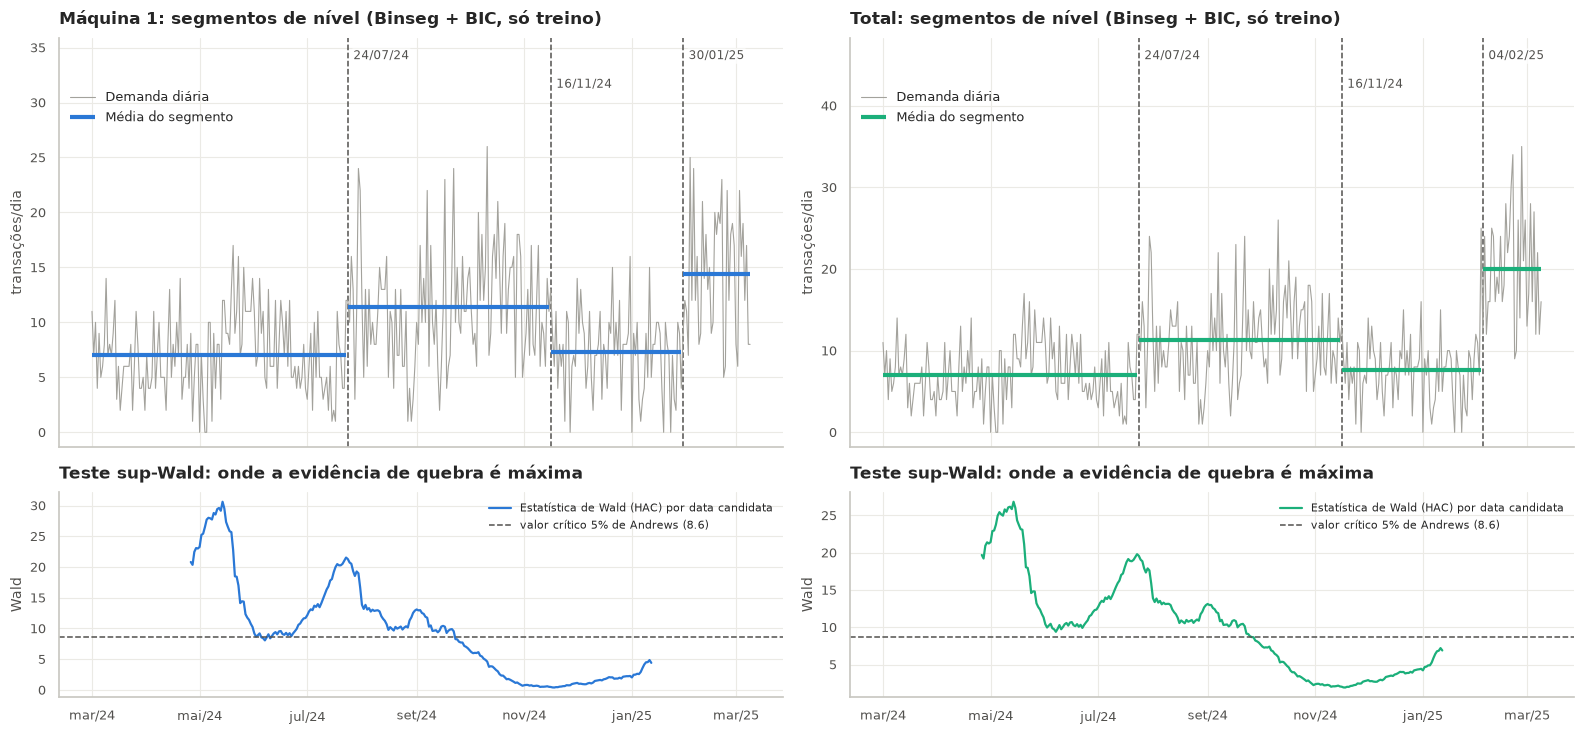

In [3]:
for serie, t in r["locais"].items():
    display(Markdown(f"**{serie}: confirmação local de cada quebra (sup-Wald no trecho entre as vizinhas)**"))
    display(t.round(3))
display(Markdown("**Regressão segmentada (±8 semanas): mudança de nível × mudança de tendência**"))
display(r["segmentadas"].round(3))
mostrar(sb.grafico_quebras(base.series, r, ORIGEM))

**Leitura:**
- **Há quebras estruturais, com evidência muito forte.**
  - O sup-Wald global rejeita a estabilidade nas duas séries (p < 0,001, contra um valor crítico de 8,6).
  - O OLS-CUSUM também rejeita.
  - As dummies de regime melhoram a verossimilhança da NB2 (LR = 102 na M1 e 154 no Total, p < 0,001).
- **Três quebras de nível na M1:**
  - 24/07/2024: 7,0 → 11,4/dia;
  - 16/11/2024: → 7,3;
  - 30/01/2025: → 14,4.

  No Total, a última é em 04/02/2025 (→ 20,0, já com a M2). Cada uma é confirmada pelo sup-Wald local (p < 0,001). O BIC com tamanho efetivo escolhe as mesmas datas, porque a autocorrelação residual é baixa (r₁ = 0,06).
- **São mudanças de nível, não de tendência.** Na regressão segmentada os saltos de nível são significativos (p ≤ 0,03), e as mudanças de inclinação não (p > 0,3). Isso justifica **dummies de patamar**, e não termos de tendência quebrada.
- **A data da maior quebra única é 14/05/2024**, a data da extensão do horário, e não a quebra de 2025. Quando se busca uma só quebra no ano, o sup-Wald global a coloca nessa data, com salto de +3,6/dia.

## 2. Quebra inicial: a janela de vendas mudou

O horário de funcionamento não é registrado. Ele é inferido pela primeira e última venda do dia. O sinal usado é a **proporção diária de vendas fora de 10h–19h** da M1.

,valor
data detectada (só treino),2024-05-18 00:00:00
data refinada (série inteira),2024-05-14 00:00:00
% fora 10–19h antes,12.451
% fora 10–19h depois,39.928
sup-Wald,131.044
p (Andrews),0.000
data sup-Wald,2024-05-17 00:00:00
Mann-Whitney p,0.000


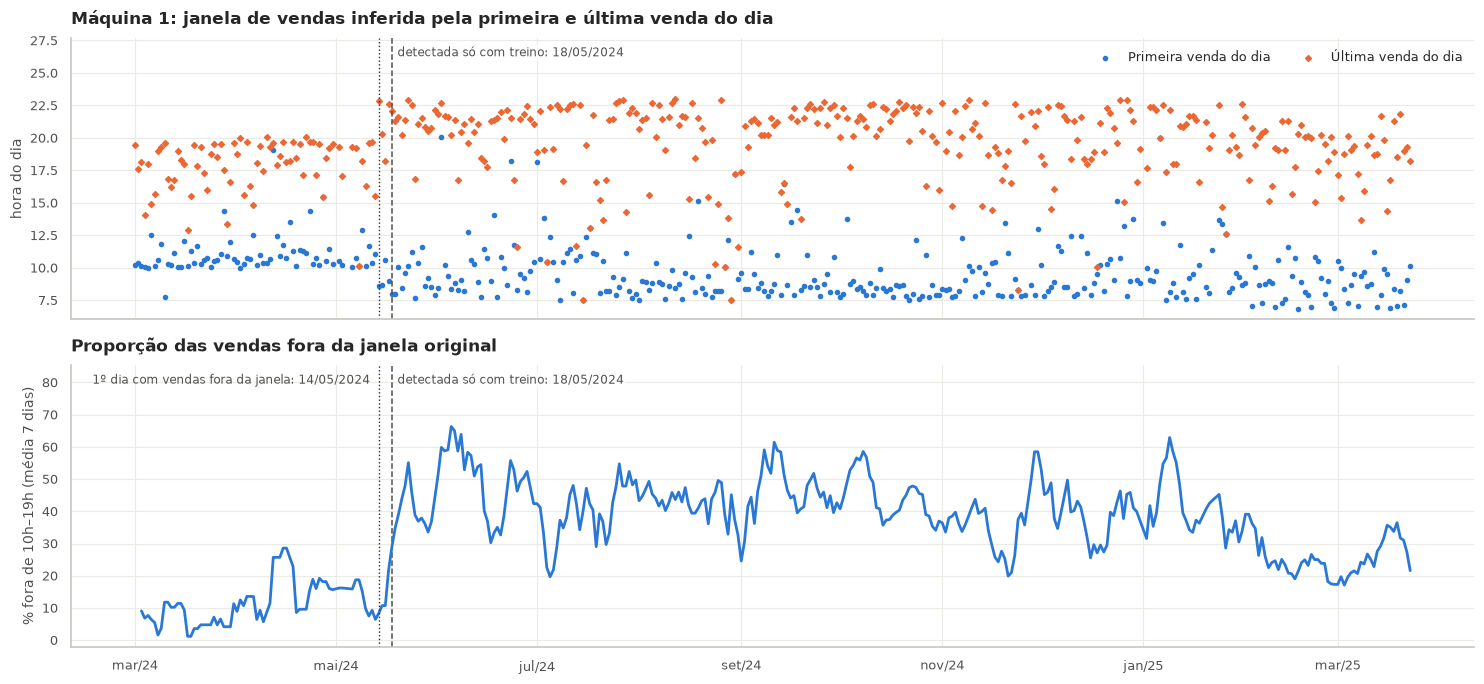

In [4]:
display(pd.Series(r["janela"]).to_frame("valor"))
mostrar(sb.grafico_janela(base.transacoes, r["janela"]["data detectada (só treino)"], r["janela"]["data refinada (série inteira)"]))

**Leitura:**
- Em **mai/2024 a janela de vendas da M1 passou de ~10h–19h para ~07h–23h**. A proporção de vendas fora de 10h–19h vai de **12% para 40%** (sup-Wald p < 0,001; Mann-Whitney p ≈ 10⁻¹⁷).
- Datas:
  - **18/05/2024** é a data detectada só com o treino, usada na modelagem;
  - **14/05/2024** é o primeiro dia com vendas fora da janela antiga, refinado com a série inteira e usado nas análises causais. É a mesma data do notebook principal, seção 19.1.
- Antes dessa data, a máquina operou com **horário reduzido**. Esse período é o que a dummy `dummy_horario_reduzido` representa.

## 3. Quebra final: o aumento de patamar está associado a novos clientes?

Proxy de cliente: o identificador `card` da **Máquina 1**. As limitações estão na docstring de `customer_analysis.py`: um cartão não é uma pessoa, vendas em dinheiro não têm ID, e a M2 não tem a coluna `card`.

Duas condições favorecem a análise. Desde jul/2024 **100% das vendas da M1 têm cartão**, então a cobertura é completa no período da quebra. E os 28 primeiros dias da série são descartados como *burn-in* (censura à esquerda: em mar/2024 todo cartão é "novo").

**Decomposição do crescimento da demanda diária da M1** (antes: 05/12/2024–29/01/2025; depois: 30/01/2025–23/03/2025)

,transações/dia antes,transações/dia depois,Δ transações/dia,% do crescimento
grupo,,,,
novos (1ª compra após a quebra),0.000,13.000,13.000,176.190
recorrentes (já vistos antes),7.020,1.400,-5.620,-76.190
sem cartão,0.000,0.000,0.000,0.000
total,7.020,14.400,7.380,100.000


Cartões ativos depois da quebra: 196 | nunca vistos antes: 177


,cartoes_unicos,transacoes,transacoes_de_novos,transacoes_recem_chegados,cartoes_novos,cartoes_recorrentes,% transações de recém-chegados,compras por cartão,válida (fora do burn-in),transacoes_sem_cartao
semana,,,,,,,,,,
2024-12-16,41,60,36,36,25,16,60.000,1.460,True,0
2024-12-23,36,55,32,39,24,12,70.910,1.530,True,0
2024-12-30,33,54,25,37,20,13,68.520,1.640,True,0
2025-01-06,30,42,25,27,19,11,64.290,1.400,True,0
2025-01-13,33,49,17,25,13,20,51.020,1.480,True,0
2025-01-20,28,37,22,26,17,11,70.270,1.320,True,0
2025-01-27,37,62,31,33,25,12,53.230,1.680,True,0
2025-02-03,48,106,94,103,44,4,97.170,2.210,True,0
2025-02-10,48,100,33,94,21,27,94.000,2.080,True,0


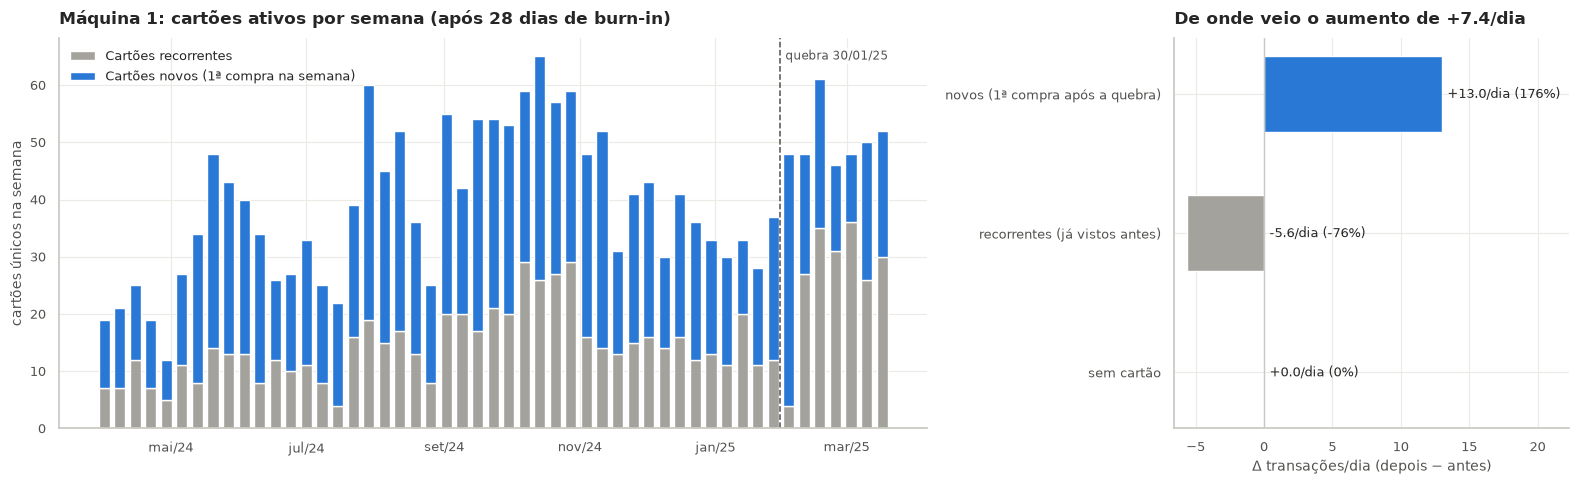

In [5]:
quebra_final = r["detector"].quebra_novos_clientes_ate("Máquina 1", ORIGEM)
sem = ca.evolucao_semanal(base.transacoes)
dec = ca.decompor_crescimento(base.transacoes, quebra_final, base.fim)
display(Markdown(f"**Decomposição do crescimento da demanda diária da M1** (antes: {dec.attrs['janela_antes']}; depois: {dec.attrs['janela_depois']})"))
display(dec.round(2))
print(f"Cartões ativos depois da quebra: {dec.attrs['cartoes_depois']} | nunca vistos antes: {dec.attrs['cartoes_novos']}")
display(sem.loc["2024-12-15":].round(2))
mostrar(ca.grafico_clientes(sem, dec, quebra_final))

In [6]:
display(Markdown("**O afluxo de recém-chegados é anormal?** (% de transações de cartões com 1ª compra nos 28 dias anteriores)"))
display(pd.Series(ca.teste_afluxo_novos(sem, quebra_final)).to_frame("valor"))
display(Markdown("**Frequência de compra (janelas de 6 semanas antes × depois)**"))
display(pd.Series(ca.comparar_frequencia(base.transacoes, quebra_final, base.fim)).to_frame("valor"))
display(Markdown("**Coortes de cartões novos (6 semanas de acompanhamento cada)**"))
display(ca.frequencia_e_retencao(base.transacoes, quebra_final, base.fim).round(2))

**O afluxo de recém-chegados é anormal?** (% de transações de cartões com 1ª compra nos 28 dias anteriores)

,valor
semanas depois,8.000
média depois (%),71.422
média histórica (%),64.389
máximo histórico de blocos de mesmo tamanho (%),70.979
p empírico (blocos históricos ≥ observado),0.000
Mann-Whitney p (semanas),0.335


**Frequência de compra (janelas de 6 semanas antes × depois)**

,valor
cartões ativos antes,164.000
cartões ativos depois,161.000
compras/cartão antes (média),1.835
compras/cartão depois (média),3.770
Mann-Whitney p,0.000


**Coortes de cartões novos (6 semanas de acompanhamento cada)**

,coorte (1ª compra a partir de),pós-quebra,cartões novos,novos por semana,compras por cartão (na janela),% que compram 2+ vezes
0,2024-03-29,False,71,11.830,1.720,42.250
1,2024-05-10,False,157,26.170,1.550,31.210
2,2024-06-21,False,138,23.000,1.480,28.990
3,2024-08-02,False,166,27.670,1.530,32.530
4,2024-09-13,False,195,32.500,1.690,36.920
5,2024-10-25,False,172,28.670,1.370,24.420
6,2024-12-06,False,122,20.330,1.560,26.230
7,2025-01-30,True,143,23.830,3.830,54.550


**Leitura: a quebra final está fortemente associada a uma troca de clientela da M1.**
- **177 dos 196 cartões ativos depois de 30/01/2025 nunca tinham comprado antes.** Os novos cartões respondem por **13,0 das 14,4 transações/dia** depois da quebra.
- Os cartões já conhecidos **caem de 7,0 para 1,4 transação/dia**. O crescimento líquido (+7,4/dia) é **mais do que explicado** pelos novos (176% do aumento), compensando a saída dos antigos.
- Na semana da quebra, 44 dos 48 cartões ativos eram novos. A proporção de transações de recém-chegados nas 8 semanas seguintes (71%) **supera o máximo histórico** de qualquer bloco de 8 semanas (71,0%; p empírico = 0). A comparação semana a semana tem pouco poder (Mann-Whitney p = 0,33), porque a proporção histórica já é alta: 30–35% dos cartões de cada semana são novos.
- **Os novos clientes compram mais vezes.**
  - A coorte pós-quebra faz **3,8 compras por cartão** em 6 semanas, contra 1,4–1,7 nas coortes anteriores, e **55%** voltam a comprar (24–42% antes).
  - A frequência por cartão ativo dobra (1,8 → 3,8 compras em 6 semanas; Mann-Whitney p < 0,001).

**Interpretação e limites.** O padrão é o de **um novo público na M1**: muitos cartões novos de uma vez, mais recorrentes que os antigos, enquanto a base antiga quase desaparece. É compatível, por exemplo, com mudança de local ou de contexto da máquina.

Não é possível afirmar a causa: cartões podem ter sido reemitidos, e uma pessoa pode ter vários cartões. A Máquina 2, sem `card`, não pode ser analisada; o crescimento dela entra no Total como uma fonte separada (notebook 01).

## 4. Quebra inicial: a mudança de horário provocou canibalização?

**Restrição dos dados.** A janela mudou em **14/05/2024**, mas a Máquina 2 só aparece em **08/02/2025**. Em 2024 **não havia outra máquina** para ganhar ou perder vendas, então a canibalização *entre máquinas* causada pela mudança de horário **não é testável**. A investigação tem duas partes separadas, ambas restritas à hipótese de canibalização:

- **(a)** a extensão de horário de 2024 canibalizou o **núcleo de horário original** (10h–19h) da M1?
- **(b)** a **entrada da M2** canibalizou a M1?

### 4(a) Extensão de horário de 2024: demanda nova ou deslocada?

Porte da seção 20.1 do notebook principal, com a mesma metodologia e a mesma semente:
- série temporal interrompida com Binomial Negativa e erros HAC, em janelas de ±6, 8 e 10 semanas;
- **taxa de incrementalidade** = Δ demanda total ÷ demanda das novas horas, com IC por bootstrap em blocos de 7 dias;
- análise dos cartões ativos dos dois lados da mudança.

janela,±6 semanas,±8 semanas,±10 semanas
total pré,6.000,5.946,6.186
total pós,9.524,8.607,7.786
núcleo pré,5.952,5.911,6.114
núcleo pós,6.024,5.446,4.986
novas horas pós,3.500,3.161,2.800
incrementalidade,1.007,0.842,0.571
IC95% inf,0.579,0.340,-0.083
IC95% sup,1.420,1.230,1.034
IRR total,1.588,1.448,1.261
p total,0.000,0.001,0.065


,valor
cartões nos dois lados,21.000
compras/semana pré (mediana),0.375
compras/semana pós (mediana),0.500
Wilcoxon p,0.498
% compras nas novas horas pré,0.000
% compras nas novas horas pós,18.042
cartões novos no pós,202.000
% 1ªs compras de novos nas novas horas,36.139
% de todas as compras pós nas novas horas,35.792


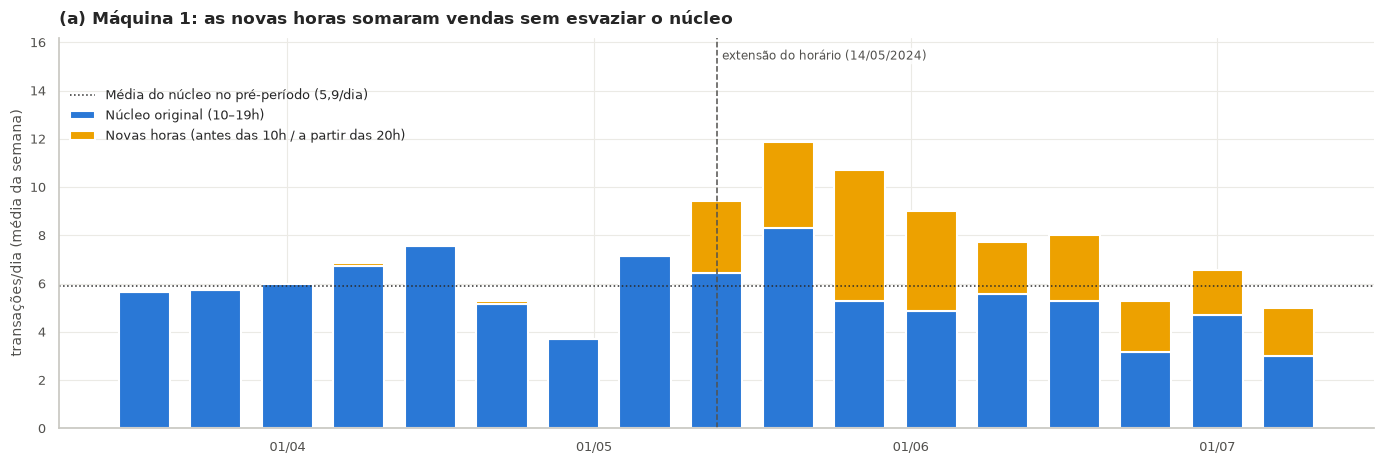

In [7]:
corte = r["janela"]["data refinada (série inteira)"]
horario = cn.analisar_mudanca_horario(base.transacoes, corte)
display(horario.round(3).T)
cartoes = cn.deslocamento_cartoes(base.transacoes, corte)
display(pd.Series(cartoes).to_frame("valor").round(3))
mostrar(cn.grafico_mudanca_horario(base.transacoes, corte))

**Leitura (a):**
- **O núcleo não cai de forma detectável.** Na janela de ±8 semanas, as vendas em 10h–19h passam de 5,9 para 5,4/dia (IRR 0,92, IC 0,72–1,18, p = 0,51). Com ±6 semanas, ficam idênticas (IRR 1,01).
- **A demanda total sobe 45%** (IRR 1,45, p = 0,001), quase toda explicada pelas ~3,2 vendas/dia das novas horas.
- **Incrementalidade de 0,84** na janela principal, com IC bootstrap de 0,34 a 1,23. Ou seja, ~84% das vendas das novas horas parecem demanda adicional. A estimativa **varia com a janela**: 1,01 com ±6 e 0,57 com ±10 semanas.
- No nível do cliente, os 21 cartões ativos dos dois lados passam a fazer 18% das compras nas novas horas, **sem reduzir a frequência** (Wilcoxon p = 0,50). É troca de horário, não perda.

**Conclusão (a): a evidência é contra uma canibalização dominante.** A extensão foi predominantemente incremental, mas uma canibalização parcial **não pode ser excluída**: o IC admite até ~2/3, e a janela de ±10 semanas sugere ~43%. É um antes/depois sem grupo de controle: sazonalidade de meio de ano ou outras mudanças de mai/2024 confundem o efeito.

### 4(b) Entrada da Máquina 2: a M1 perdeu vendas?

O pré-período começa na quebra de patamar da M1 (30/01), para não confundir o efeito da M2 com o salto anterior. Ele tem só **9 dias**, então o teste de nível tem baixo poder. Por isso há evidências complementares:
- composição horária da M1;
- fim de semana (onde a M2 é forte);
- correlação diária, já que substituição gera correlação negativa nos mesmos dias;
- participação da M2 ao longo do tempo.

,valor
pré-período,30/01–07/02/2025
média M1 pré,14.222
média M1 pós,14.432
IRR (pós M2),1.063
IC95% inf (pós M2),0.929
IC95% sup (pós M2),1.217
p (pós M2),0.374
ρ Spearman M1 × M2 (diário),-0.110
p (nula circular),0.818
IRR (interação pós × fim de semana),0.758


,M1 antes (trans./dia),M1 depois (trans./dia),M2 depois (trans./dia),M1 Δ (trans./dia),% M1 antes,% M1 depois,% M2
faixa,,,,,,,
Abertura (06–09h),1.260,2.450,0.680,1.190,15.740,17.010,11.450
Núcleo manhã (10–13h),2.120,4.180,1.640,2.060,26.490,28.980,27.480
Núcleo tarde (14–19h),3.580,7.340,2.980,3.760,44.720,50.870,50.000
Fechamento (20–23h),1.050,0.450,0.660,-0.590,13.050,3.150,11.070


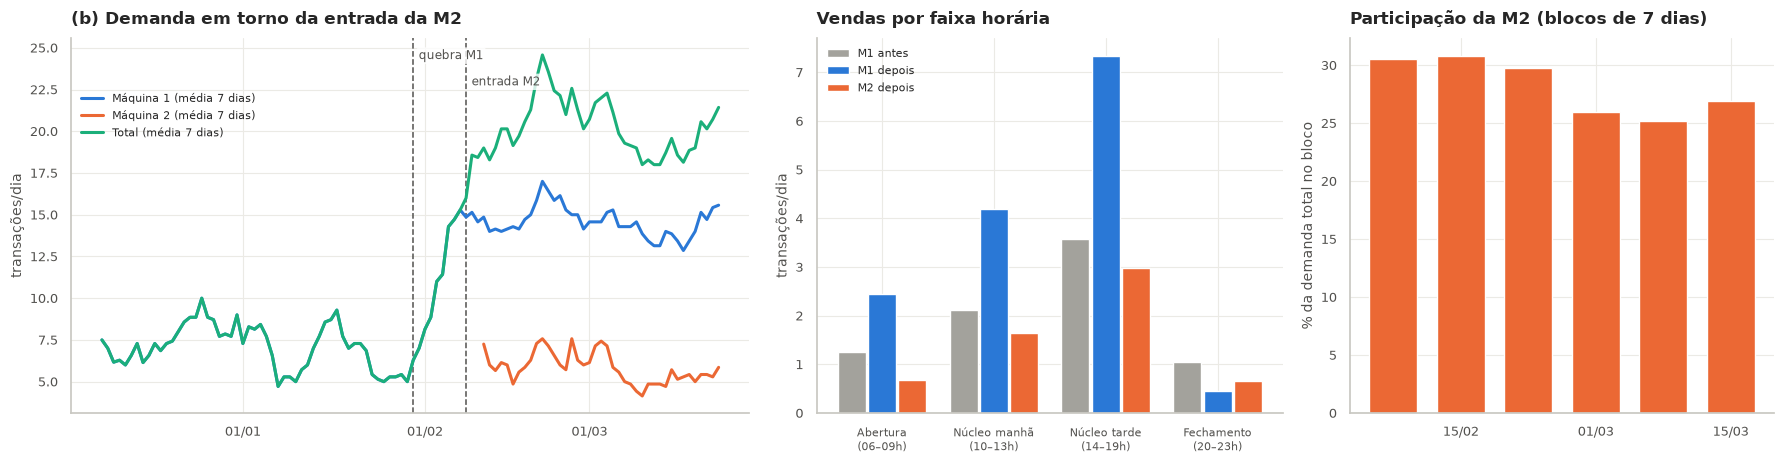

In [8]:
m2 = cn.analisar_entrada_m2(base.transacoes, base.series, base.inicio["Máquina 2"], quebra_final, base.fim)
display(pd.Series({**m2["nivel"], **m2["correlacao"], **m2["fim_de_semana"], "χ² composição horária da M1 (p)": m2["qui_quadrado_p"]}).to_frame("valor"))
display(m2["composicao"].round(2))
mostrar(cn.grafico_entrada_m2(m2, base.series, base.inicio["Máquina 2"], quebra_final))

In [9]:
display(Markdown("**Síntese das evidências a favor e contra a canibalização**"))
display(cn.sintese_evidencias(horario, cartoes, m2).style.hide(axis="index"))

**Síntese das evidências a favor e contra a canibalização**

parte,evidência,observado,leitura
(a) horário 2024,Núcleo (10–19h) após a extensão,"5.9 → 5.4/dia (IRR 0.92, p = 0.51)",contra canibalização forte (núcleo não cai de forma detectável)
(a) horário 2024,Demanda total após a extensão,IRR 1.45 (p = 0.001),a extensão somou demanda
(a) horário 2024,Taxa de incrementalidade (±6/8/10 sem.),"1.01, 0.84, 0.57; IC95% ±8 sem. [0.34; 1.23]",predominantemente incremental; canibalização parcial não excluída (IC largo)
(a) horário 2024,Cartões recorrentes,0% → 18% das compras nas novas horas; frequência 0.38 → 0.50/sem. (Wilcoxon p = 0.50),"há troca de horário individual, sem queda de frequência (n pequeno)"
(b) entrada da M2,Nível da M1 após a entrada da M2,"14.2 → 14.4/dia (IRR 1.06, p = 0.37)",contra canibalização líquida: sem queda detectável da M1 (pré-período de 9 dias: baixo poder)
(b) entrada da M2,"M1 no fechamento (20–23h), faixa forte da M2",1.05 → 0.45/dia; composição horária da M1 antes × depois: χ² p = 0.000,a favor de deslocamento localizado: a M1 perde no fechamento quase o que a M2 vende nessa faixa; confundido com a troca de público da M1 (seção 6.2)
(b) entrada da M2,Fim de semana da M1 (a M2 vende 41% no fim de semana),interação pós × fim de semana: IRR 0.76 (p = 0.07),indício fraco (não significativo a 5%) de queda da M1 nos dias fortes da M2
(b) entrada da M2,Correlação diária M1 × M2,ρ = -0.11 (p circular = 0.82),substituição diária não detectada (seria ρ negativo)
(b) entrada da M2,Participação da M2 ao longo das semanas,ρ = -0.77 (p = 0.07),sem ganho progressivo de participação às custas da M1


**Leitura (b):**
- **Não há queda líquida da M1 após a entrada da M2.** A M1 passa de 14,2 para 14,4/dia (IRR 1,06, IC 0,93–1,22). A demanda **total** sobe pelo volume da M2: nada indica que o mercado só se redistribuiu.
- **Há um indício localizado no horário noturno.** As vendas da M1 entre 20h e 23h caem de 1,05 para 0,45/dia, perto do que a M2 vende nessa faixa (0,66/dia), e a composição horária da M1 muda (χ² p < 0,001). Mas essa queda é **confundida com a troca de público da M1** (seção 3): os novos clientes compram mais de manhã e à tarde, e a queda noturna já era visível no mapa mês × hora do notebook principal.
- **No fim de semana**, dias fortes da M2, a M1 cresce menos que nos dias úteis (IRR da interação 0,76, IC 0,56–1,03). O efeito não é significativo a 5%: é um indício fraco.
- **Não há substituição diária** (ρ = −0,11, p circular = 0,82) nem ganho progressivo de participação da M2.

**Conclusão (b):** os dados **não sustentam canibalização líquida** da M1 pela M2. Há sinais localizados (noite e fim de semana) compatíveis com um deslocamento parcial de clientes, mas que não se separam da mudança de público da M1. Com 44 dias de convivência, o poder é limitado.

## 5. Datas das dummies (fundamentação para o notebook 04)

| Dummy | Definição | Data na modelagem (só treino) | Evidência |
|---|---|---|---|
| `dummy_horario_reduzido` | 1 do início da série até a véspera da extensão do horário | **18/05/2024** (refinada: 14/05/2024) | Binseg + BIC na % de vendas fora de 10h–19h (12% → 40%); sup-Wald p < 0,001; maior quebra única da demanda da M1 em 14/05/2024 |
| `dummy_novos_clientes` | 1 a partir do aumento de patamar de 2025 | **30/01/2025** (M1) e **04/02/2025** (Total) | Binseg + BIC + sup-Wald local (p < 0,001); 177 de 196 cartões ativos depois são novos |

Em cada origem do backtest as datas são **redetectadas com os dados até ela**. Enquanto a quebra de 2025 não é detectável (até ~3 semanas depois de acontecer), `dummy_novos_clientes` simplesmente não existe naquela origem. As quebras intermediárias (24/07 e 16/11/2024) entram como dummies de regime **candidatas**, e cada modelo decide se as usa.